# 04 · Paper tables and figures

This notebook reads the trial-level records and regenerates the tables and vector figures. Paired savings use the same clip, training seed, horizon, placeholder, and delay for both methods in each comparison. The aggregate averages the three seed-level medians.

In [1]:
import json
import os
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "study.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tinyml.config import DATASETS, RESULTS, SEEDS, run_dir

REBUILD = os.environ.get("TINYML_NOTEBOOK_REBUILD") == "1"
DATA = Path(os.environ.get("TINYML_DATA_DIR", ROOT / "data")).resolve()
WORKERS = os.environ.get("TINYML_NOTEBOOK_WORKERS", "2")
SCRATCH = ROOT / "build" / "notebooks"

def run(*args):
    command = [sys.executable, *map(str, args)]
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout + result.stderr)
        result.check_returncode()
    return result.stdout + result.stderr

print("Execution mode:", "full reproduction" if REBUILD else "inspect archived outputs")
print("Models:", len(DATASETS) * len(SEEDS), "| seeds:", ", ".join(map(str, SEEDS)))

Execution mode: full reproduction
Models: 6 | seeds: 13, 37, 73


In [2]:
from tinyml.analysis import run as analyze
from IPython.display import Image

summary = analyze()
assert summary["native_mismatches"] == summary["renode_mismatches"] == 0
display(pd.DataFrame(summary["primary"]).T.round(2))

,renode_cases_per_seed,adaptive_savings_pct_seed_mean,adaptive_savings_pct_seed_sd,adaptive_win_pct_seed_mean,slowest_adaptive_savings_pct,max_observed_adaptive_sram_bytes
wisdm,306.0,27.93,1.20,83.33,-3.63,3714.0
mhealth,204.0,35.63,0.76,89.54,-3.92,3420.0


In [3]:
for name in ("table_01_models", "table_02_renode", "table_03_ablations",
             "table_04_memory", "table_05_bursts", "table_06_letter"):
    display(Markdown((RESULTS / "tables" / f"{name}.md").read_text()))

Clean held-out classification. Scores are mean ± sample SD over three training seeds on fixed subject splits.

| Dataset | Train/val/test subjects | Test windows | FP32 accuracy (%) | INT8 accuracy (%) | INT8 macro-F1 (%) |
| --- | ---: | ---: | ---: | ---: | ---: |
| WISDM | 34/7/10 | 2,668 | 42.1 ± 1.3 | 41.2 ± 0.8 | 40.9 ± 0.7 |
| MHEALTH | 5/2/3 | 864 | 52.2 ± 5.2 | 52.5 ± 6.1 | 49.2 ± 7.5 |


Cortex-M4 emulation at history 48. Instruction quantiles are computed within each seed and averaged across seeds. Saved is the mean ± sample SD of seed medians of matched per-case percentage savings versus replay. SRAM is the maximum observed live method state plus repair stack. All compared scores agreed with the oracle.

| Method | WISDM median (k) | WISDM saved (%) | WISDM p95 (k) | WISDM SRAM (B) | MHEALTH median (k) | MHEALTH saved (%) | MHEALTH p95 (k) | MHEALTH SRAM (B) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Replay | 255.3 | 0.0 ± 0.0 | 493.1 | 3,618 | 236.6 | 0.0 ± 0.0 | 456.6 | 3,324 |
| Span | 187.2 | 20.2 ± 0.0 | 352.7 | 3,714 | 172.1 | 23.6 ± 0.0 | 316.9 | 3,420 |
| Tap mask | 127.2 | 27.5 ± 0.0 | 347.5 | 3,714 | 130.8 | 29.8 ± 0.0 | 317.8 | 3,420 |
| Tap + equality | 128.2 | 28.1 ± 1.2 | 314.8 | 3,714 | 116.4 | 35.7 ± 0.7 | 290.9 | 3,420 |
| Span + equality | 189.6 | 20.7 ± 0.0 | 348.4 | 3,714 | 171.3 | 25.2 ± 1.4 | 312.1 | 3,420 |
| Adaptive + equality | 128.4 | 27.9 ± 1.2 | 314.6 | 3,714 | 116.6 | 35.6 ± 0.8 | 290.7 | 3,420 |
| Serial | 177.4 | 4.3 ± 0.0 | 955.1 | 3,714 | 166.7 | 13.9 ± 3.2 | 833.6 | 3,420 |
| Adaptive, no equality | 127.4 | 27.4 ± 0.0 | 346.8 | 3,714 | 130.9 | 30.0 ± 0.0 | 316.9 | 3,420 |


Paired ablations. Positive savings favor the named change. The instruction and MAC subsets have different sizes. The placeholder experiment uses common emulated delays only.

| Change | WISDM inst. saved (%) | WISDM wins (%) | WISDM MACs saved (%) | MHEALTH inst. saved (%) | MHEALTH wins (%) | MHEALTH MACs saved (%) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Tap dependencies without equality | 7.2 ± 0.0 | 66.0 | 13.3 ± 0.0 | 12.1 ± 0.0 | 69.1 | 12.4 ± 0.0 |
| Tap dependencies with equality | 13.0 ± 0.6 | 72.4 | 16.6 ± 0.7 | 17.3 ± 1.8 | 80.6 | 17.5 ± 0.3 |
| INT8 equality with tap masks | -1.4 ± 0.0 | 31.0 | 0.0 ± 0.0 | -0.5 ± 0.5 | 44.1 | 0.3 ± 0.3 |
| INT8 equality with dense spans | -1.3 ± 0.0 | 12.7 | 0.0 ± 0.0 | -1.4 ± 0.0 | 26.3 | 0.0 ± 0.0 |
| INT8 equality with adaptive masks | -1.4 ± 0.0 | 29.6 | 0.0 ± 0.0 | -0.9 ± 0.5 | 42.0 | 0.1 ± 0.3 |
| Density switching versus tap masks | 0.0 ± 0.0 | 22.1 | 0.0 ± 0.0 | -0.1 ± 0.0 | 21.1 | 0.0 ± 0.0 |
| Batching on burst arrivals | 60.3 ± 0.4 | 88.9 | 52.8 ± 0.2 | 58.0 ± 0.5 | 97.2 | 51.4 ± 0.0 |
| Last observation versus zero placeholder | 2.5 ± 0.9 | 59.3 | — | 5.3 ± 1.4 | 66.7 | — |


Memory ablation. Coverage uses only paired single-sample and four-sample cases with ages 8, 24, and 48 on the native corpus. Stack is the maximum observed Cortex-M4 watermark. If an update is too old, the entire transaction is rejected.

| Dataset | Max age | State (B) | Stack (B) | SRAM (B) | Accepted (%) |
| --- | ---: | ---: | ---: | ---: | ---: |
| MHEALTH | 8 | 992 | 220 | 1,212 | 33.3 |
| MHEALTH | 24 | 1,872 | 228 | 2,100 | 66.7 |
| MHEALTH | 48 | 3,192 | 228 | 3,420 | 100.0 |
| WISDM | 8 | 1,046 | 220 | 1,266 | 33.3 |
| WISDM | 24 | 2,022 | 228 | 2,250 | 66.7 |
| WISDM | 48 | 3,486 | 228 | 3,714 | 100.0 |


Emulated burst batching versus applying the same updates one at a time.

| Dataset | Burst size | Cases | Instructions saved (%) | Wins (%) |
| --- | ---: | ---: | ---: | ---: |
| WISDM | 2 | 162 | 32.5 ± 0.1 | 85.2 |
| WISDM | 4 | 162 | 60.7 ± 0.1 | 88.9 |
| WISDM | 8 | 162 | 75.7 ± 0.1 | 92.6 |
| MHEALTH | 2 | 108 | 32.5 ± 0.3 | 91.7 |
| MHEALTH | 4 | 108 | 59.9 ± 0.7 | 100.0 |
| MHEALTH | 8 | 108 | 75.2 ± 0.3 | 100.0 |


Proposed correction versus replay at a 48-sample horizon. Saved is the mean ± sample SD of three within-seed medians. Faster is the share of paired cases with lower instruction count. Accuracy describes the clean held-out INT8 classifier.

| Dataset | Saved (%) | Faster (%) | SRAM (B) | Acc. (%) |
| --- | ---: | ---: | ---: | ---: |
| WISDM | 27.9 ± 1.2 | 83.3 | 3,714 | 41.2 |
| MHEALTH | 35.6 ± 0.8 | 89.5 | 3,420 | 52.5 |


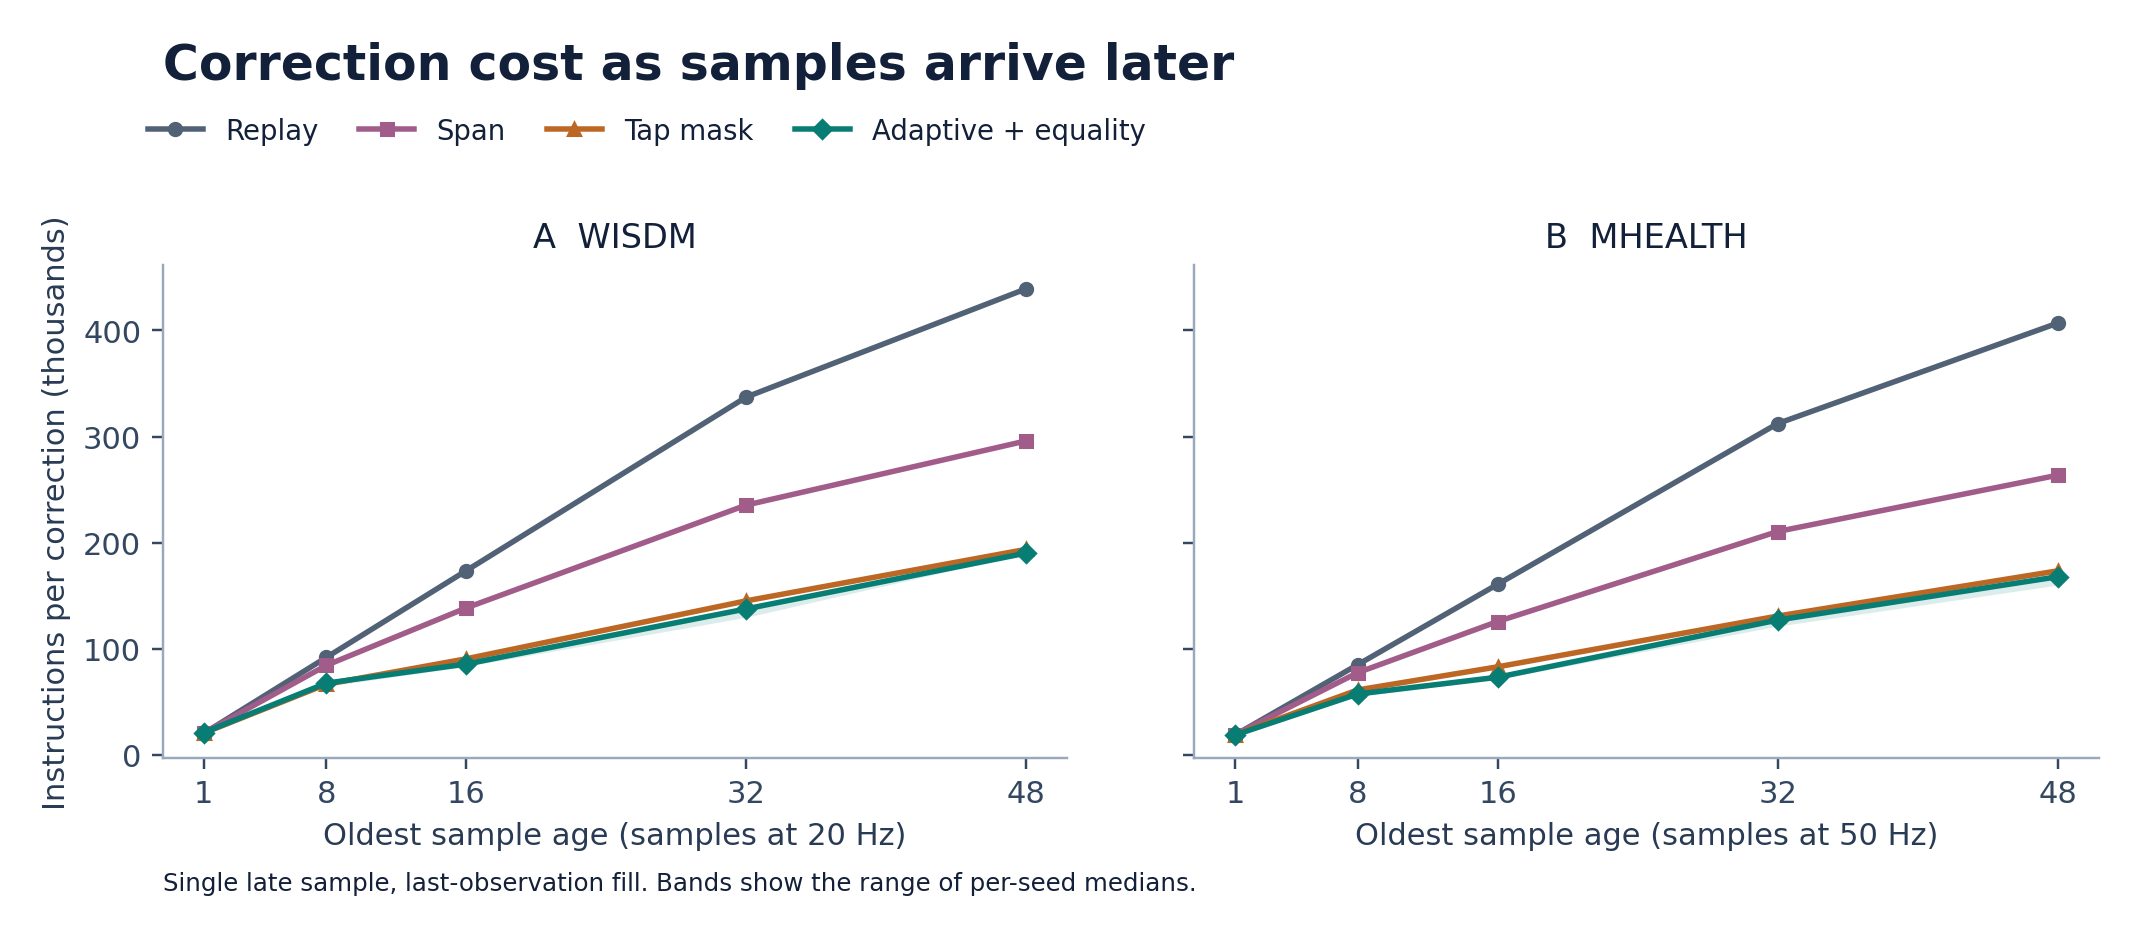

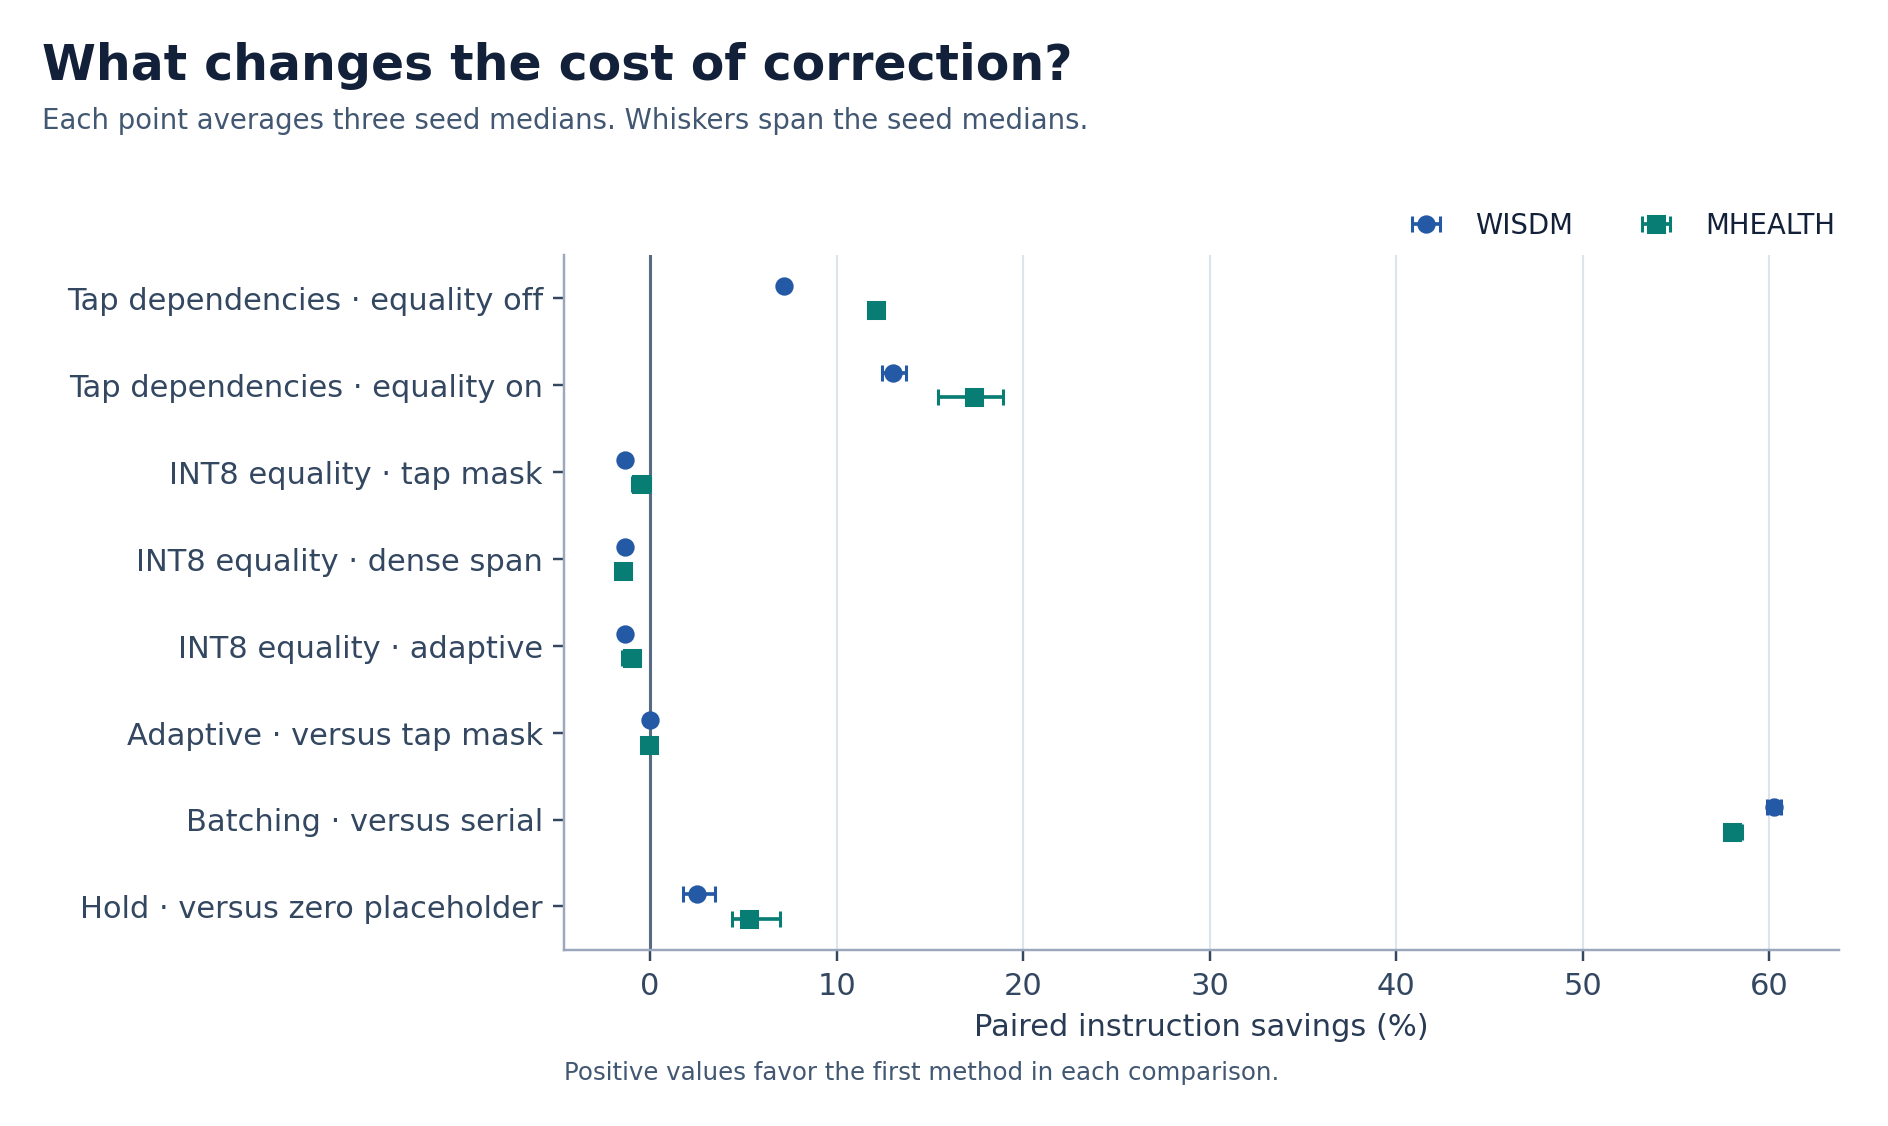

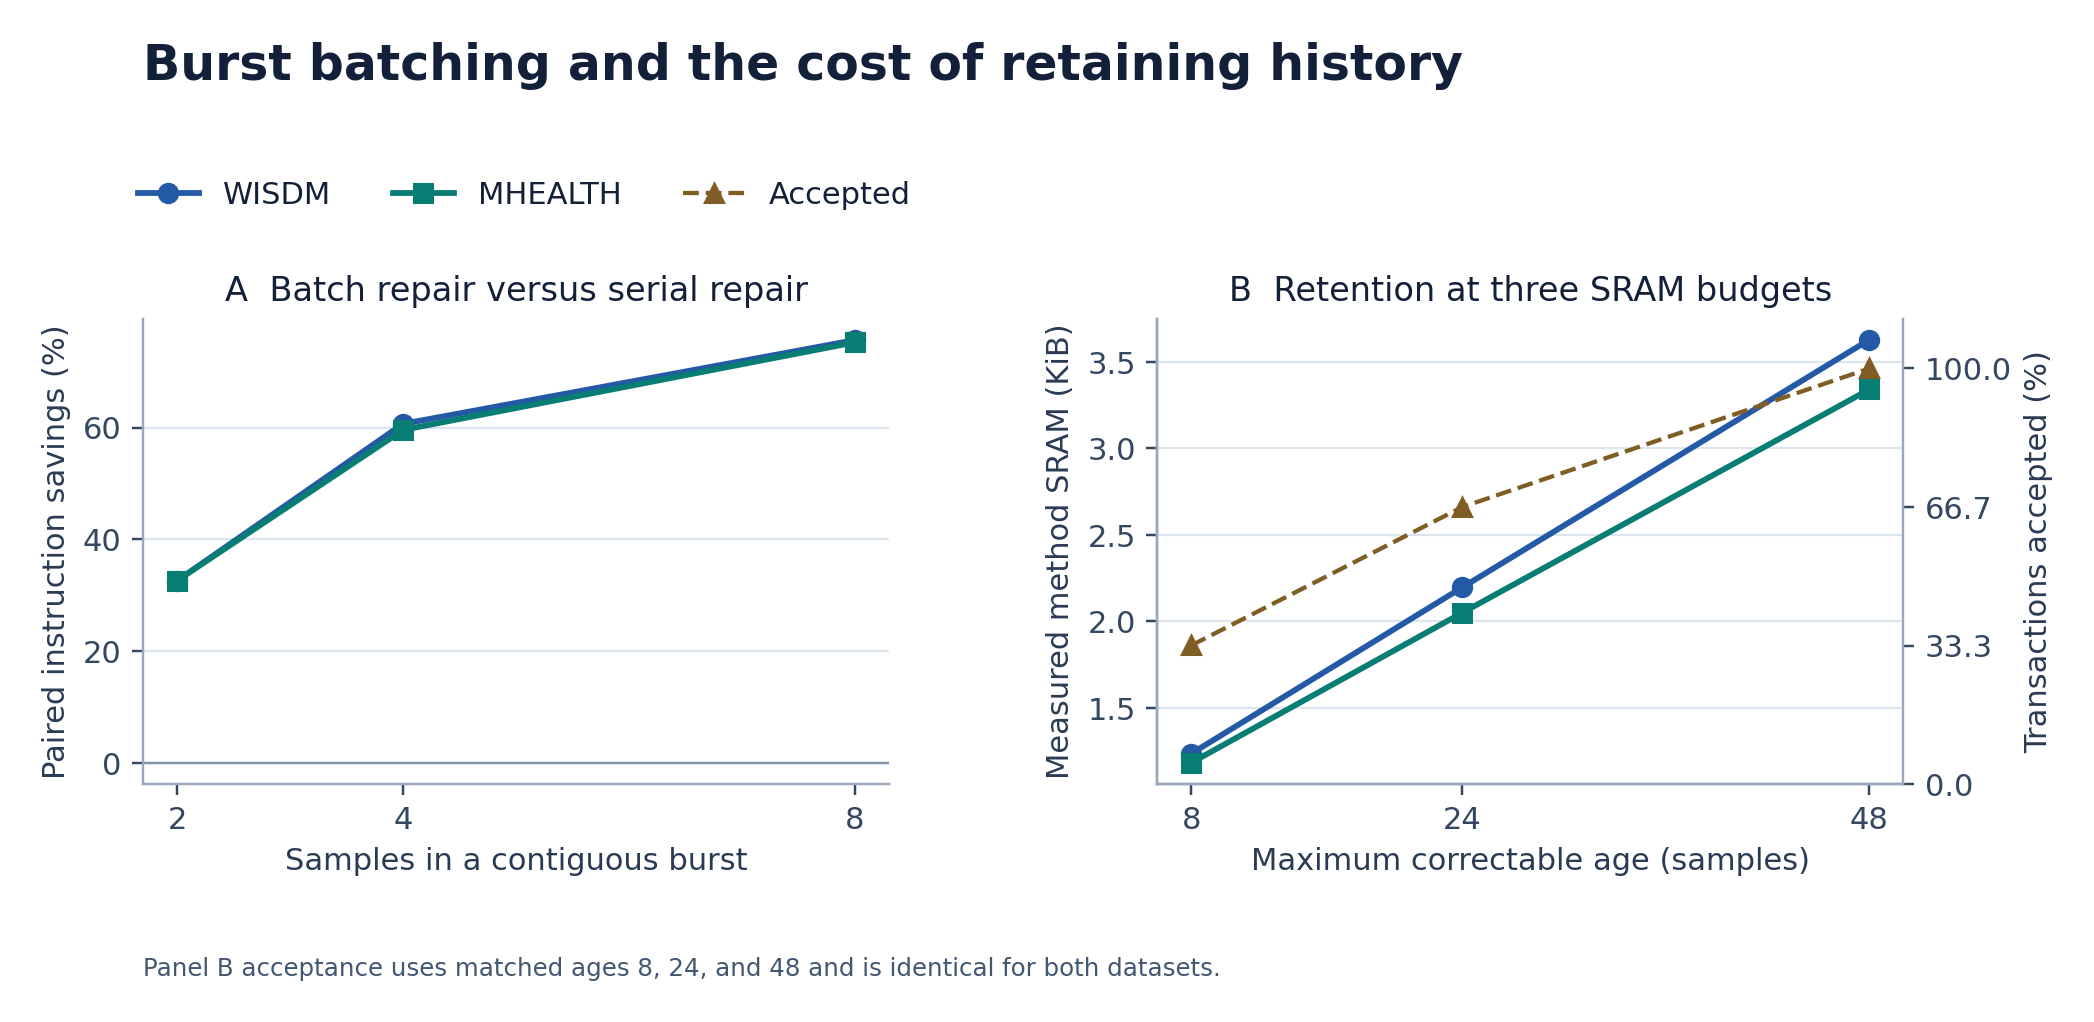

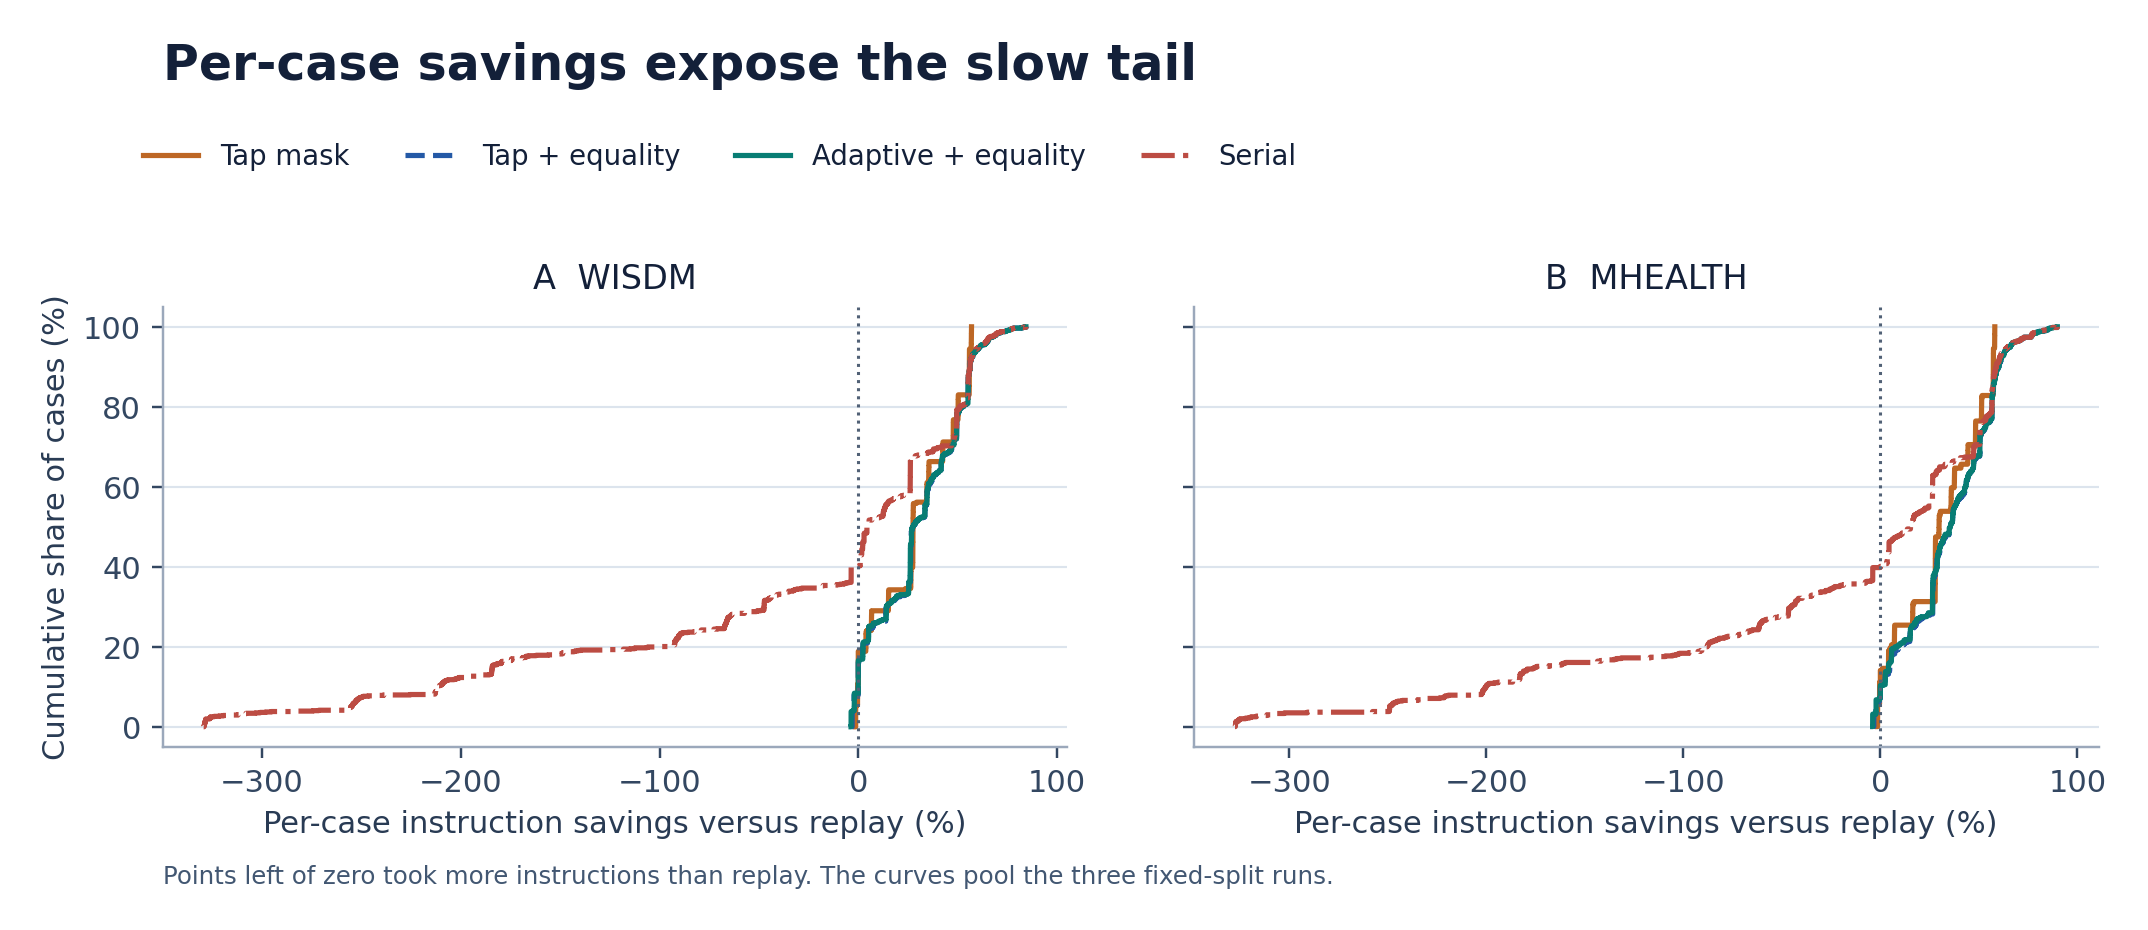

In [4]:
for name in ("fig_01_delay", "fig_02_ablations", "fig_03_bursts_memory", "fig_04_distribution"):
    display(Image(filename=str(ROOT / "figures" / f"{name}.png"), width=940, embed=True))

The replay savings are measured on controlled delay scenarios. The equality ablations show a trade-off between avoiding downstream recomputation and paying for comparisons. The reported seed variation uses one fixed subject split per dataset.